In [ ]:
%load_ext autoreload
%autoreload 2

In [44]:
import warnings

warnings.filterwarnings("ignore")

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from haversine import haversine_vector

from synccfd.simulator.generator import DatasetGenerator

sns.set_style("darkgrid")
sns.set(font_scale=1.4)

# Toy Example

In [17]:
# Generate the data
city_radius = 12
available_terminals_radius = 10
start_date = "2025-01-01"

generator = DatasetGenerator(
    n_customers=5,
    n_terminals=25,
    nb_days=5,
    city_radius=city_radius,
    available_terminals_radius=available_terminals_radius,
    start_date=start_date,
    random_state=42,
)
customer_profiles_table, terminal_profiles_table, transactions_df = generator.generate()

# Persist the dataset explicitly (opt-in in v0.1.0)
generator.save(save_format="pkl")

Creating terminal profiles: 100%|██████████| 25/25 [00:00<00:00, 39976.21it/s]


Computing available terminals for each customer (CP Txs)...


Generating transactions: 100%|██████████| 5/5 [00:00<00:00, 218.87it/s]



Adding fraudulent transactions:
Applying fraud scenario 1: High amount fraud...
Applying fraud scenario 2: Compromised terminals...


Applying fraud scenarios 3 and 4: 100%|██████████| 5/5 [00:00<00:00, 1664.01it/s]


Dataset generation completed!

Dataset saved successfully!


In [45]:
# Data can be loaded back from disk after save()
BEGIN_DATE = "2025-01-01"
END_DATE = "2025-01-05"

data = DatasetGenerator()
txs = data.read_transactions(
    begin_date=BEGIN_DATE, end_date=END_DATE, save_format="pkl", data_dir="data"
)

## Customer profiles table

In [18]:
print(customer_profiles_table.shape)
customer_profiles_table

(5, 8)


,CUSTOMER_ID,billing_lat,billing_long,mean_amount,std_amount,mean_nb_tx_per_day,cnp_prob,available_terminals
0,0,-22.665501,-42.709487,57.137283,28.568641,2.860757,0.602763,[]
1,1,-23.562391,-46.538513,56.763902,28.381951,1.694619,0.645894,"[0, 1, 3, 4, 6, 7, 8, 11, 12, 13, 15, 16, 17, ..."
2,2,-23.503953,-46.608595,46.570785,23.285393,3.567092,0.963663,"[1, 3, 4, 6, 8, 11, 13, 15, 17, 18, 23, 24]"
3,3,-22.719713,-43.317747,41.426944,20.713472,3.166900,0.528895,[21]
4,4,-21.742437,-46.557300,58.964233,29.482117,3.702387,0.071036,[]


## Terminal profiles table

In [19]:
print(terminal_profiles_table.shape)
terminal_profiles_table

(25, 3)


,TERMINAL_ID,terminal_lat,terminal_long
0,0,-23.591063,-46.571248
1,1,-23.566478,-46.567424
2,2,-22.801569,-42.742336
3,3,-23.587611,-46.584168
4,4,-23.479757,-46.566502
5,5,-23.595310,-46.660138
6,6,-23.546753,-46.537242
7,7,-23.621043,-46.474076
8,8,-23.559136,-46.564159
9,9,-23.640379,-46.630841


## Transactions table

In [20]:
print(transactions_df.shape)
transactions_df

(84, 16)


,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,TX_AMOUNT,TX_TYPE,TX_SHIPP_LAT,TX_SHIPP_LONG,TX_BILL_LAT,TX_BILL_LONG,TX_TERM_LAT,TX_TERM_LONG,TX_TIME_SECONDS,TX_TIME_DAYS,TX_FRAUD,TX_FRAUD_SCENARIO
0,0,2025-01-01 01:41:43,2,1,39.15,CNP,-23.503953,-46.608595,-23.503953,-46.608595,-23.566478,-46.567424,6103,0,0,0
1,1,2025-01-01 03:59:41,3,0,34.20,CNP,-22.759945,-43.332079,-22.719713,-43.317747,-23.591063,-46.571248,14381,0,0,0
2,2,2025-01-01 04:29:52,4,7,46.63,CNP,-21.742437,-46.557300,-21.742437,-46.557300,-23.621043,-46.474076,16192,0,0,0
3,3,2025-01-01 06:16:27,1,24,41.77,CNP,-23.562391,-46.538513,-23.562391,-46.538513,-23.481370,-46.517897,22587,0,0,0
4,4,2025-01-01 07:46:53,3,18,7.68,CNP,-22.719713,-43.317747,-22.719713,-43.317747,-23.569300,-46.558694,28013,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,79,2025-01-05 18:08:32,3,20,30.19,CNP,-22.719713,-43.317747,-22.719713,-43.317747,-23.557286,-46.528274,410912,4,0,0
80,80,2025-01-05 20:03:58,4,17,82.41,CNP,-21.742437,-46.557300,-21.742437,-46.557300,-23.566453,-46.561059,417838,4,1,2
81,81,2025-01-05 20:17:13,2,8,11.10,CNP,-23.555584,-46.544252,-23.503953,-46.608595,-23.559136,-46.564159,418633,4,0,0
82,82,2025-01-05 21:54:34,4,8,73.00,CNP,-21.742437,-46.557300,-21.742437,-46.557300,-23.559136,-46.564159,424474,4,0,0


In [21]:
# Getting transactions for a specific customer from our previously generated dataset
customer_id = 1
transaction_table_customer = transactions_df[
    transactions_df["CUSTOMER_ID"] == customer_id
]
transaction_table_customer

,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,TX_AMOUNT,TX_TYPE,TX_SHIPP_LAT,TX_SHIPP_LONG,TX_BILL_LAT,TX_BILL_LONG,TX_TERM_LAT,TX_TERM_LONG,TX_TIME_SECONDS,TX_TIME_DAYS,TX_FRAUD,TX_FRAUD_SCENARIO
3,3,2025-01-01 06:16:27,1,24,41.77,CNP,-23.562391,-46.538513,-23.562391,-46.538513,-23.481370,-46.517897,22587,0,0,0
7,7,2025-01-01 09:30:22,1,6,34.00,CP,-23.546753,-46.537242,-23.562391,-46.538513,-23.546753,-46.537242,34222,0,0,0
20,20,2025-01-02 00:33:17,1,19,98.26,CP,-23.612871,-46.514263,-23.562391,-46.538513,-23.612871,-46.514263,88397,1,0,0
28,28,2025-01-02 08:54:18,1,3,13.97,CNP,-23.562391,-46.538513,-23.562391,-46.538513,-23.587611,-46.584168,118458,1,0,0
41,41,2025-01-03 11:17:42,1,12,77.48,CNP,-23.562391,-46.538513,-23.562391,-46.538513,-23.606227,-46.584678,213462,2,0,0
51,51,2025-01-04 01:55:36,1,3,83.20,CNP,-23.562391,-46.538513,-23.562391,-46.538513,-23.587611,-46.584168,266136,3,0,0
57,57,2025-01-04 13:50:15,1,17,111.08,CP,-23.566453,-46.561059,-23.562391,-46.538513,-23.566453,-46.561059,309015,3,1,2
72,72,2025-01-05 07:37:17,1,19,55.15,CP,-23.612871,-46.514263,-23.562391,-46.538513,-23.612871,-46.514263,373037,4,0,0
77,77,2025-01-05 13:20:10,1,24,32.64,CNP,-23.562391,-46.538513,-23.562391,-46.538513,-23.481370,-46.517897,393610,4,0,0


## Plotting locations

In [22]:
loc_features = generator.get_location_features()

### Setting the information to plot locations ###
world = loc_features.data["world_data"]
brazil = world[world.name == "Brazil"]

# Transforming the data into a GeoDataFrame in order to draw
billing_locs = gpd.GeoDataFrame(
    customer_profiles_table,
    geometry=gpd.points_from_xy(
        customer_profiles_table.billing_long, customer_profiles_table.billing_lat
    ),
)

billing_cities_locs = loc_features.billing_cities_locations
billing_cities_locs = gpd.GeoDataFrame(
    billing_cities_locs,
    geometry=gpd.points_from_xy(billing_cities_locs.long, billing_cities_locs.lat),
)

terminal_locs = gpd.GeoDataFrame(
    terminal_profiles_table,
    geometry=gpd.points_from_xy(
        terminal_profiles_table.terminal_long, terminal_profiles_table.terminal_lat
    ),
)


terminal_cities_locs = loc_features.terminal_cities_locations
terminal_cities_locs = gpd.GeoDataFrame(
    terminal_cities_locs,
    geometry=gpd.points_from_xy(terminal_cities_locs.long, terminal_cities_locs.lat),
)

available_terminals_ids = [
    terminal_id
    for sub_list in customer_profiles_table["available_terminals"]
    for terminal_id in sub_list
]  # Creating a single list with all the available terminals
available_terminals_ids = list(
    set(available_terminals_ids)
)  # Removing the possible duplicated id's

available_terminal_locs = terminal_locs.loc[available_terminals_ids]


# Getting info for a single customer txs locations
customer_txs = transactions_df.loc[
    transactions_df["CUSTOMER_ID"] == customer_id,
    [
        "CUSTOMER_ID",
        "TERMINAL_ID",
        "TX_BILL_LAT",
        "TX_BILL_LONG",
        "TX_TERM_LAT",
        "TX_TERM_LONG",
        "TX_SHIPP_LAT",
        "TX_SHIPP_LONG",
    ],
]

tx_bill_locs = customer_txs[["TX_BILL_LAT", "TX_BILL_LONG"]]
tx_term_locs = customer_txs[["TX_TERM_LAT", "TX_TERM_LONG"]]
tx_shipp_locs = customer_txs[["TX_SHIPP_LAT", "TX_SHIPP_LONG"]]

tx_bill_locs = gpd.GeoDataFrame(
    tx_bill_locs,
    geometry=gpd.points_from_xy(tx_bill_locs.TX_BILL_LONG, tx_bill_locs.TX_BILL_LAT),
)
tx_term_locs = gpd.GeoDataFrame(
    tx_term_locs,
    geometry=gpd.points_from_xy(tx_term_locs.TX_TERM_LONG, tx_term_locs.TX_TERM_LAT),
)
tx_shipp_locs = gpd.GeoDataFrame(
    tx_shipp_locs,
    geometry=gpd.points_from_xy(
        tx_shipp_locs.TX_SHIPP_LONG, tx_shipp_locs.TX_SHIPP_LAT
    ),
)

### Billing and terminal locations

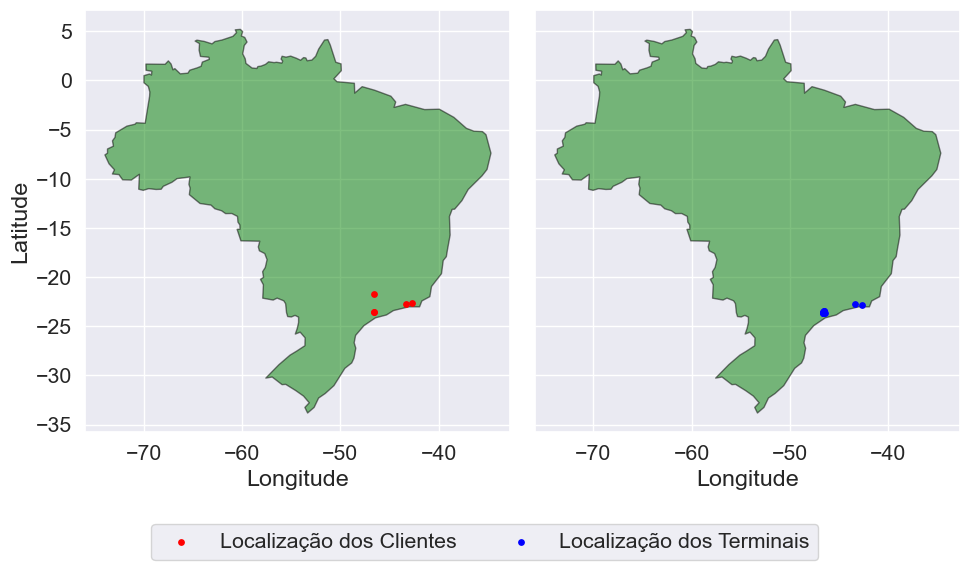

In [23]:
fig, axs = plt.subplots(1, 2, figsize=(10, 14), sharey=True)

brazil.plot(color="green", edgecolor="black", alpha=0.5, ax=axs[0])
billing_locs.plot(
    color="red", markersize=15, label="Localização dos Clientes", ax=axs[0]
)

brazil.plot(color="green", edgecolor="black", alpha=0.5, ax=axs[1])
terminal_locs.plot(
    color="blue", markersize=15, label="Localização dos Terminais", ax=axs[1]
)

axs[0].set_xlabel("Longitude")
axs[1].set_xlabel("Longitude")
axs[0].set_ylabel("Latitude")

# To create a single legend for subplots
handles = []
labels = []
for ax in axs:
    h, l = ax.get_legend_handles_labels()
    handles.extend(h)
    labels.extend(l)

fig.legend(handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0.25))

plt.tight_layout()
plt.show()

### Available terminals locations

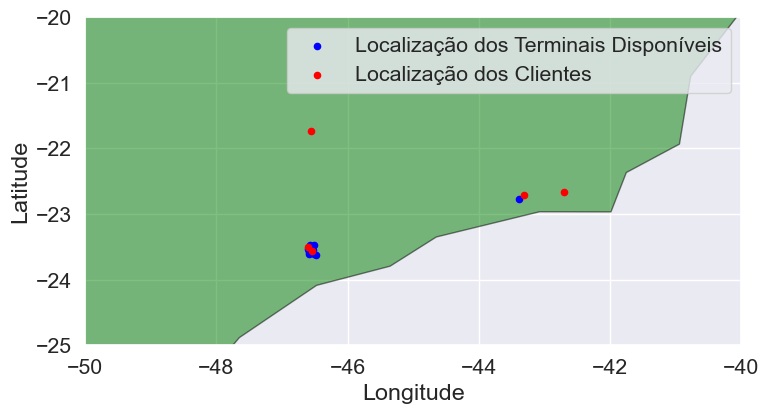

In [24]:
fig, axs = plt.subplots(1, 1, figsize=(8, 7))

brazil.plot(color="green", edgecolor="black", alpha=0.5, ax=axs)
available_terminal_locs.plot(
    color="blue", markersize=20, label="Localização dos Terminais Disponíveis", ax=axs
)
billing_locs.plot(color="red", markersize=20, label="Localização dos Clientes", ax=axs)

plt.xlim([-50, -40])
plt.ylim([-25, -20])

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.legend()
plt.tight_layout()
plt.show()

### Transaction Locations

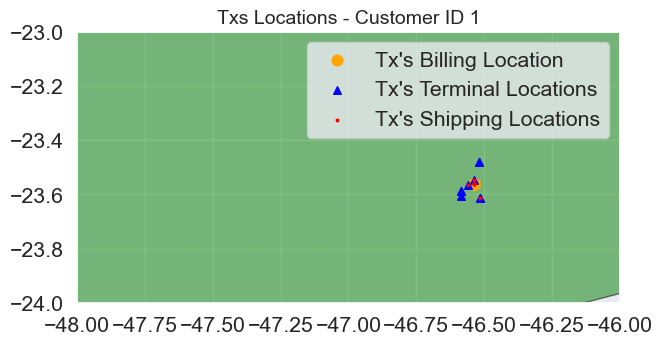

In [25]:
fig, axs = plt.subplots(1, 1, figsize=(7, 7))

brazil.plot(color="green", edgecolor="black", alpha=0.5, ax=axs)
tx_bill_locs.plot(
    ax=axs, color="orange", marker="o", markersize=60, label="Tx's Billing Location"
)
tx_term_locs.plot(
    ax=axs, color="blue", marker="^", markersize=30, label="Tx's Terminal Locations"
)
tx_shipp_locs.plot(
    ax=axs, color="red", marker="*", markersize=5, label="Tx's Shipping Locations"
)

plt.xlim([-48, -46])
plt.ylim([-24, -23])

plt.legend()
plt.title(f"Txs Locations - Customer ID {customer_id}", fontsize=14)
plt.show()

# Analyzing the larger dataset

In [26]:
city_radius = 12
available_terminals_radius = 10
start_date = "2025-01-01"
n_customers = 10000
n_terminals = 20000
nb_days = 180

# Building a larger transactions dataset
generator = DatasetGenerator(
    n_customers=n_customers,
    n_terminals=n_terminals,
    nb_days=nb_days,
    city_radius=city_radius,
    available_terminals_radius=available_terminals_radius,
    start_date=start_date,
    random_state=42,
)
customer_profiles_table, terminal_profiles_table, transactions_df = generator.generate()

Creating terminal profiles: 100%|██████████| 20000/20000 [00:00<00:00, 191858.89it/s]


Computing available terminals for each customer (CP Txs)...


Generating transactions: 100%|██████████| 10000/10000 [05:19<00:00, 31.26it/s]



Adding fraudulent transactions:
Applying fraud scenario 1: High amount fraud...
Applying fraud scenario 2: Compromised terminals...


Applying fraud scenarios 3 and 4: 100%|██████████| 180/180 [03:28<00:00,  1.16s/it]



Dataset generation completed!

Dataset saved successfully!


In [27]:
transactions_df.head()

,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,TX_AMOUNT,TX_TYPE,TX_SHIPP_LAT,TX_SHIPP_LONG,TX_BILL_LAT,TX_BILL_LONG,TX_TERM_LAT,TX_TERM_LONG,TX_TIME_SECONDS,TX_TIME_DAYS,TX_FRAUD,TX_FRAUD_SCENARIO
0,0,2025-01-01 00:00:00,7973,8489,80.67,CP,-18.855654,-41.938311,-18.853632,-41.932667,-18.855654,-41.938311,0,0,0,0
1,1,2025-01-01 00:00:04,4613,12399,54.59,CNP,-9.744979,-37.624961,-9.744979,-37.624961,-21.406912,-48.502011,4,0,0,0
2,2,2025-01-01 00:00:05,7815,13861,90.45,CNP,-15.777202,-47.839018,-15.777202,-47.839018,-8.396508,-35.063068,5,0,0,0
3,3,2025-01-01 00:00:23,538,4579,101.57,CNP,-22.843596,-47.615747,-22.843596,-47.615747,-15.792099,-47.892311,23,0,0,0
4,4,2025-01-01 00:00:26,5026,19950,109.16,CNP,-3.290315,-45.202546,-3.290315,-45.202546,-22.876779,-43.228597,26,0,0,0


In [28]:
vis_transactions_df = transactions_df.head().round(3)
vis_transactions_df["TX_AMOUNT"] = vis_transactions_df["TX_AMOUNT"].astype(str)
vis_transactions_df["TX_BILL_LOC"] = (
    "("
    + vis_transactions_df["TX_BILL_LAT"].astype(str)
    + ", "
    + vis_transactions_df["TX_BILL_LONG"].astype(str)
    + ")"
)
vis_transactions_df["TX_TERM_LOC"] = (
    "("
    + vis_transactions_df["TX_TERM_LAT"].astype(str)
    + ", "
    + vis_transactions_df["TX_TERM_LONG"].astype(str)
    + ")"
)
vis_transactions_df["TX_SHIPP_LOC"] = (
    "("
    + vis_transactions_df["TX_SHIPP_LAT"].astype(str)
    + ", "
    + vis_transactions_df["TX_SHIPP_LONG"].astype(str)
    + ")"
)

In [29]:
df_styled = (
    vis_transactions_df[
        [
            "TRANSACTION_ID",
            "TX_DATETIME",
            "CUSTOMER_ID",
            "TERMINAL_ID",
            "TX_AMOUNT",
            "TX_TYPE",
            "TX_BILL_LOC",
            "TX_TERM_LOC",
            "TX_SHIPP_LOC",
            "TX_FRAUD",
        ]
    ]
    .rename(
        columns={
            "TRANSACTION_ID": "ID",
            "CUSTOMER_ID": "CUSTOMER",
            "TERMINAL_ID": "TERMINAL",
        }
    )
    .style.format({"TX_DATETIME": lambda t: t.strftime("%d/%m/%y %H:%M:%S")})
    .hide()
)

### Plotting the distribution of transaction amounts and transaction times

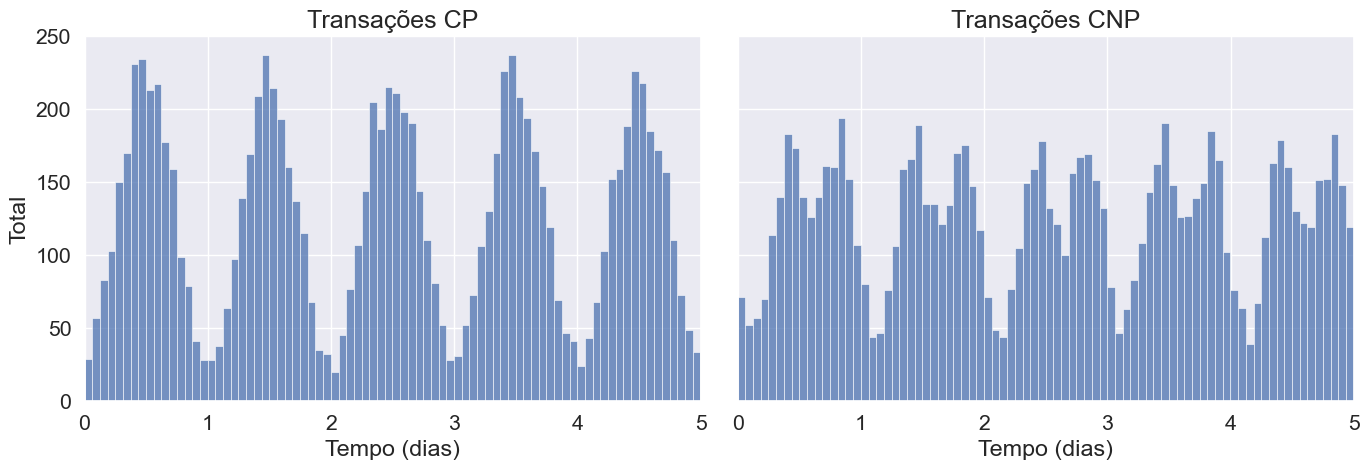

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

time_val_CP = (
    transactions_df[
        (transactions_df.TX_TYPE == "CP") & (transactions_df.TX_TIME_DAYS < 5)
    ]["TX_TIME_SECONDS"]
    .sample(n=10000, random_state=42)
    .values
)
time_val_CNP = (
    transactions_df[
        (transactions_df.TX_TYPE == "CNP") & (transactions_df.TX_TIME_DAYS < 5)
    ]["TX_TIME_SECONDS"]
    .sample(n=10000, random_state=42)
    .values
)

# Dividing the time variables by 86400 to transform seconds to days in the plot
sns.histplot(time_val_CP / 86400, ax=ax[0], color="b", bins=80, kde=False)
ax[0].set_title("Transações CP", fontsize=18)
ax[0].set_xlim([min(time_val_CP / 86400), max(time_val_CNP / 86400)])
ax[0].set_ylim([0, 250])
ax[0].set_xticks(range(6))
ax[0].set(xlabel="Tempo (dias)", ylabel="Total")
sns.histplot(time_val_CNP / 86400, ax=ax[1], color="b", bins=80, kde=False)
ax[1].set_title("Transações CNP", fontsize=18)
ax[1].set_xlim([min(time_val_CNP / 86400), max(time_val_CNP / 86400)])
ax[1].set_ylim([0, 250])
ax[1].set_xticks(range(6))

ax[1].set(xlabel="Tempo (dias)", ylabel="")

plt.tight_layout()
plt.show()

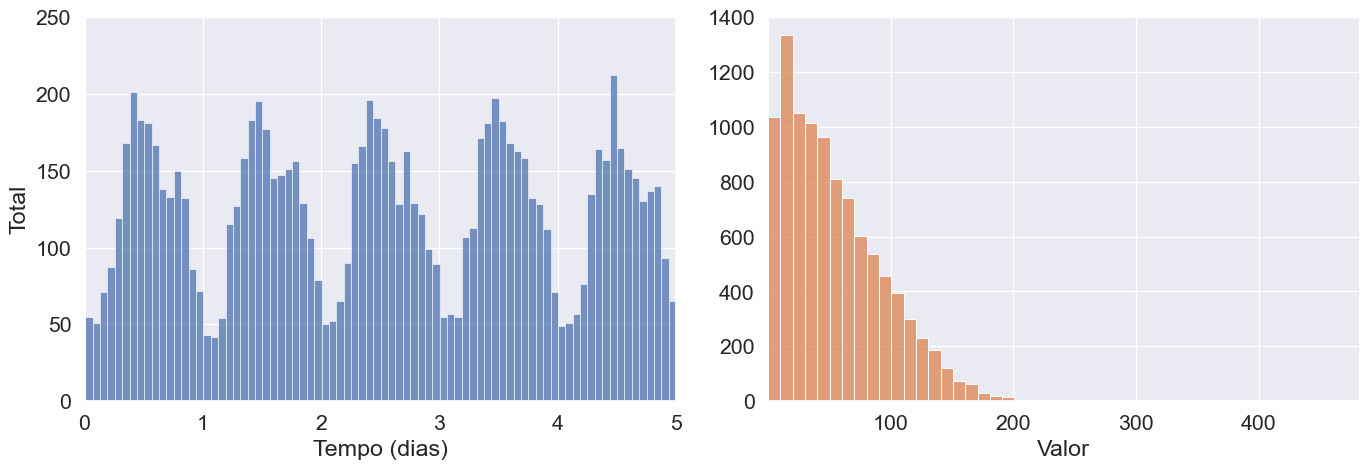

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

amount_val = (
    transactions_df[transactions_df.TX_TIME_DAYS < 5]["TX_AMOUNT"]
    .sample(n=10000, random_state=42)
    .values
)
time_val = (
    transactions_df[transactions_df.TX_TIME_DAYS < 5]["TX_TIME_SECONDS"]
    .sample(n=10000, random_state=42)
    .values
)

# We divide the time variables by 86400 to transform seconds to days in the plot
sns.histplot(time_val / 86400, ax=ax[0], color="b", bins=80, kde=False)
# ax[0].set_title('Distribuição do horário das transações')
ax[0].set_xlim([min(time_val / 86400), max(time_val / 86400)])
ax[0].set_xticks(range(6))
ax[0].set(xlabel="Tempo (dias)", ylabel="Total")
ax[0].set_ylim([0, 250])


sns.histplot(amount_val, ax=ax[1], color=sns.color_palette()[1], binwidth=10, kde=False)
# ax[1,1].set_title('Distribuição do valor das transações')
ax[1].set_xlim([min(amount_val), max(amount_val)])
ax[1].set(xlabel="Valor", ylabel="")

plt.tight_layout()
plt.show()

### CP - CNP proportion

In [32]:
print(
    transactions_df["TX_TYPE"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .astype(str)
    + "%"
)

TX_TYPE
CNP    54.38%
CP     45.62%
Name: proportion, dtype: object


### TODO: Location Features

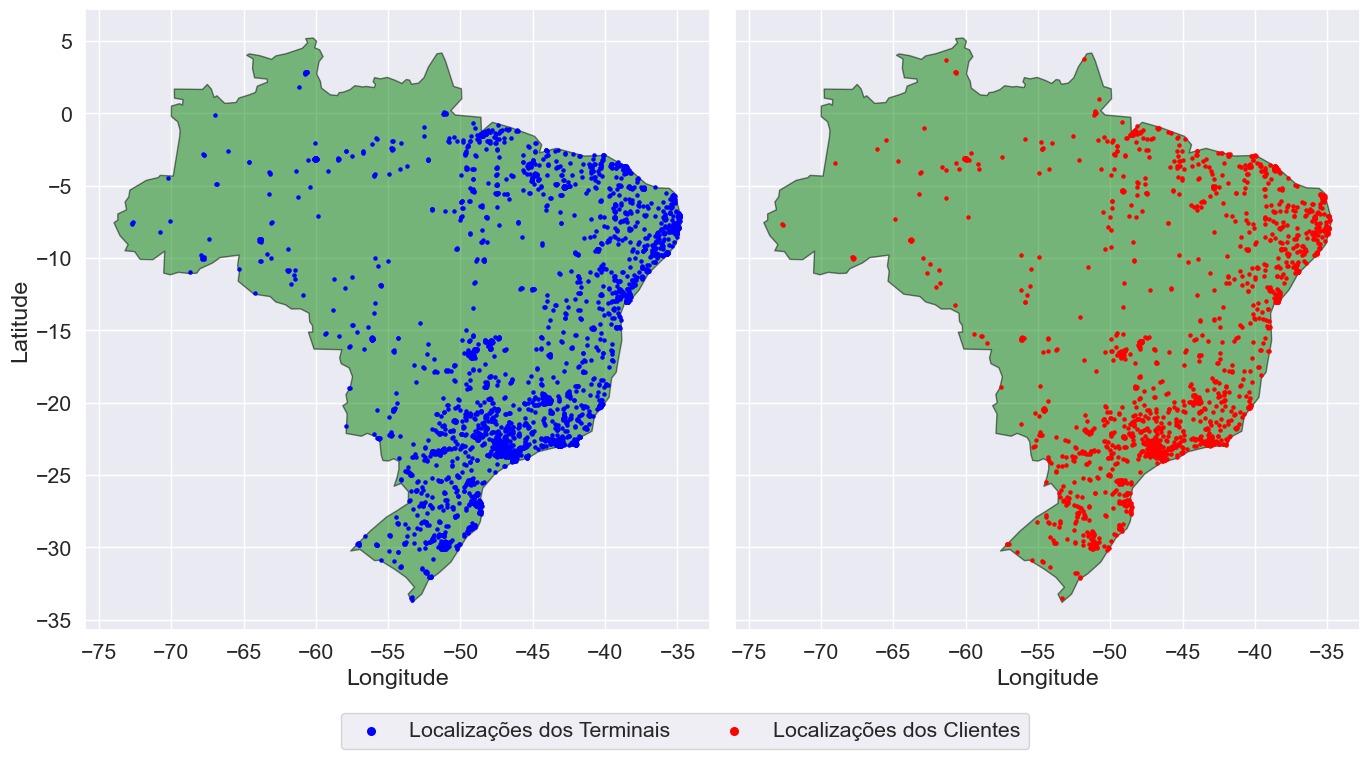

In [33]:
customers_df = customer_profiles_table.sample(n=int(0.2 * n_customers), random_state=42)
customers_geodf = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(customers_df.billing_long, customers_df.billing_lat)
)
terminals_df = terminal_profiles_table.sample(n=int(0.2 * n_terminals), random_state=42)
terminals_geodf = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(terminals_df.terminal_long, terminals_df.terminal_lat)
)

fig, axs = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
brazil.plot(facecolor="green", edgecolor="black", alpha=0.5, ax=axs[0])
terminals_geodf.plot(
    color="blue", markersize=5, ax=axs[0], label="Localizações dos Terminais"
)
brazil.plot(facecolor="green", edgecolor="black", alpha=0.5, ax=axs[1])
customers_geodf.plot(
    color="red", markersize=5, ax=axs[1], label="Localizações dos Clientes"
)

axs[0].set_xlabel("Longitude")
axs[1].set_xlabel("Longitude")
axs[0].set_ylabel("Latitude")

# To create a single legend for subplots
handles = []
labels = []
for ax in axs:
    h, l = ax.get_legend_handles_labels()
    handles.extend(h)
    labels.extend(l)

leg = fig.legend(
    handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.05)
)
leg.legend_handles[0]._sizes = [30]
leg.legend_handles[1]._sizes = [30]


plt.tight_layout()

plt.show()

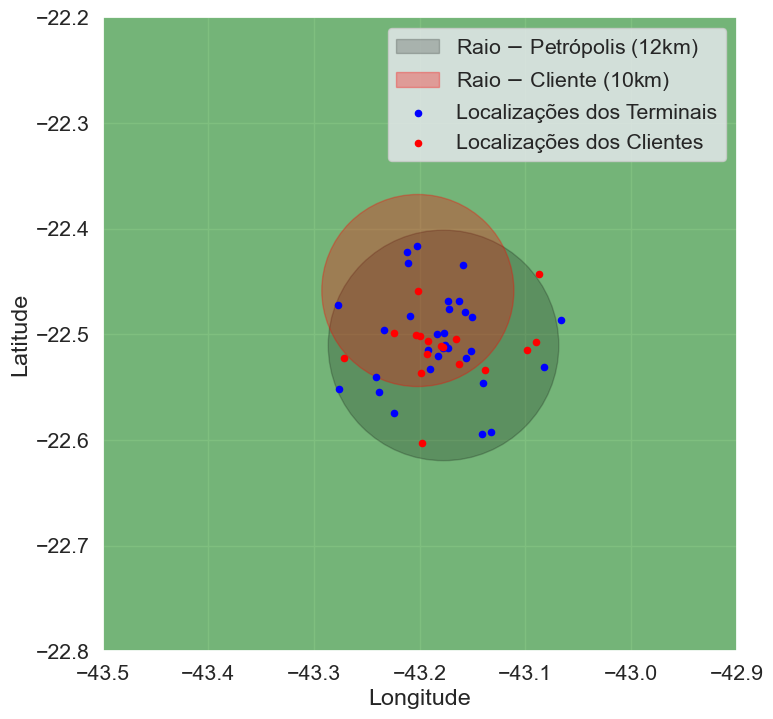

In [34]:
loc_features = generator.get_location_features()

single_city_billings = loc_features.billing_cities_locations.reset_index()
single_city_billings = single_city_billings[single_city_billings.name == "Petrópolis"]
city_center = (single_city_billings.iloc[0].long, single_city_billings.iloc[0].lat)

single_city_customers = customer_profiles_table.iloc[single_city_billings.index]
single_city_customers_gpd = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(
        single_city_customers.billing_long, single_city_customers.billing_lat
    )
)

single_city_term_locs = loc_features.terminal_cities_locations.reset_index()
single_city_term_locs = single_city_term_locs[
    single_city_term_locs.name == "Petrópolis"
]

single_city_terminals = terminal_profiles_table.iloc[single_city_term_locs.index]
single_city_terminals_gpd = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(
        single_city_terminals.terminal_long, single_city_terminals.terminal_lat
    )
)

fig, axs = plt.subplots(1, 1, figsize=(8, 8))

degrees_per_km = 1.0 / 110

brazil.plot(facecolor="green", edgecolor="black", alpha=0.5, ax=axs)

city_radius_deg = city_radius * degrees_per_km
city_circ = plt.Circle(
    city_center,
    radius=city_radius_deg,
    color="black",
    alpha=0.2,
    label="Raio $-$ Petrópolis (12km)",
)
axs.add_patch(city_circ)


customer = single_city_customers_gpd.iloc[0].geometry
available_terminals_radius_deg = available_terminals_radius * degrees_per_km
customer_circ = plt.Circle(
    (customer.x, customer.y),
    radius=available_terminals_radius_deg,
    color="red",
    alpha=0.3,
    label="Raio $-$ Cliente (10km)",
)
axs.add_patch(customer_circ)

single_city_terminals_gpd.plot(
    color="blue", markersize=20, ax=axs, label="Localizações dos Terminais"
)
single_city_customers_gpd.plot(
    color="red", markersize=20, ax=axs, label="Localizações dos Clientes"
)

plt.xlim([-43.5, -42.9])
plt.ylim([-22.8, -22.2])

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.tight_layout()

plt.show()

### Locations distribution based on population

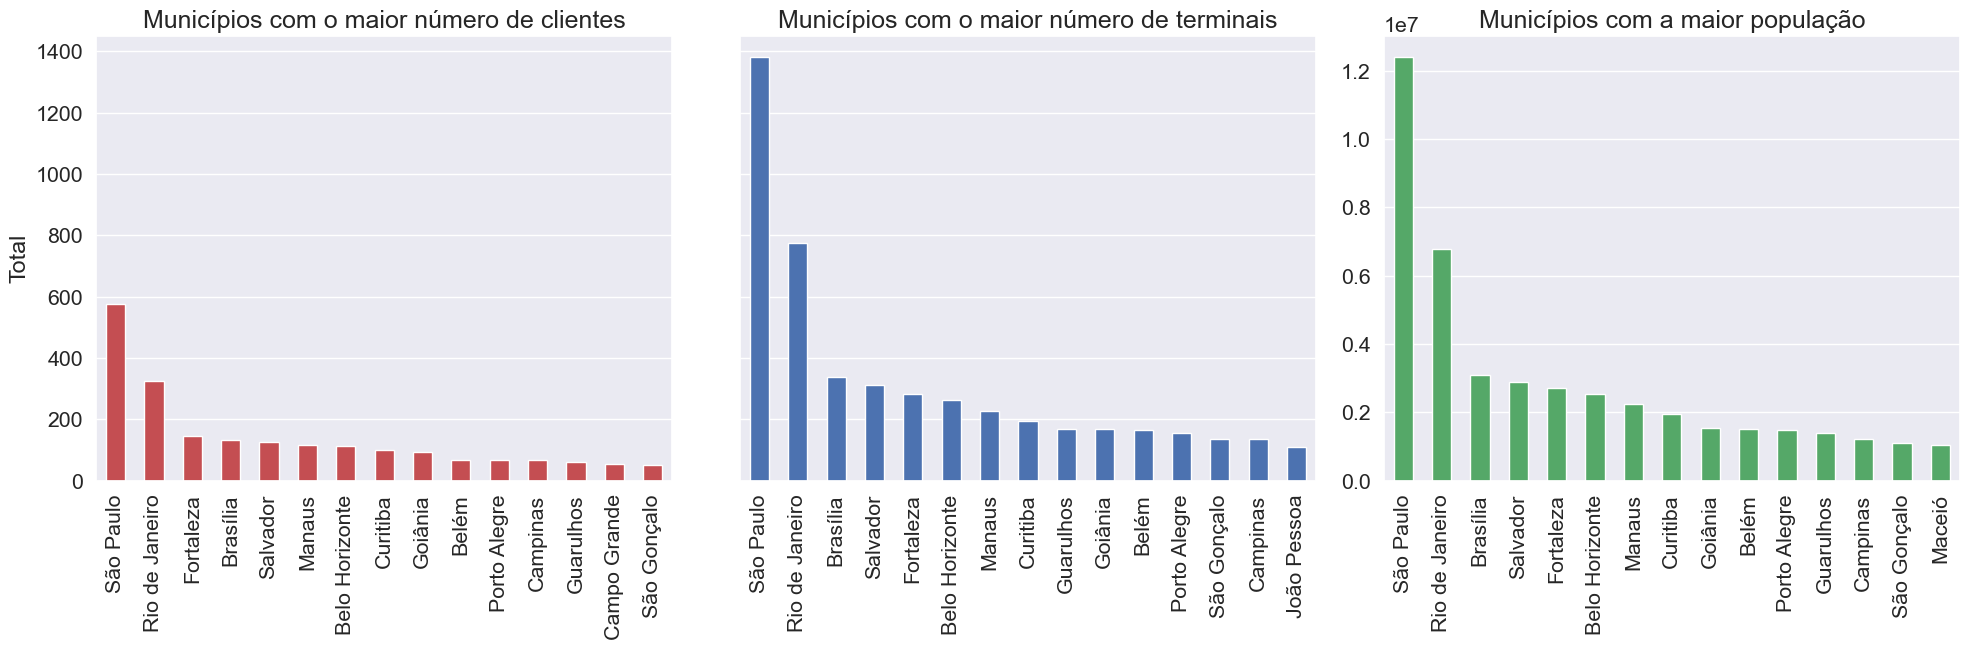

In [35]:
fig, axs = plt.subplots(1, 3, figsize=(20, 7))

customers_cities = loc_features.billing_cities_locations["name"]
customers_cities.value_counts().nlargest(15).plot(
    kind="bar", color=sns.color_palette()[3], xlabel="", ax=axs[0]
)
axs[0].set_title("Municípios com o maior número de clientes", fontsize=18)
axs[0].grid(axis="x")
axs[0].set_ylabel("Total")

customers_cities = loc_features.terminal_cities_locations["name"]
customers_cities.value_counts().nlargest(15).plot(
    kind="bar", color=sns.color_palette()[0], ax=axs[1], xlabel=""
)
axs[1].set_title("Municípios com o maior número de terminais", fontsize=18)
axs[1].grid(axis="x")
axs[0].sharey(axs[1])

plt.subplot(1, 3, 3)
loc_features.data["brazil_cities"][["name", "pop_21"]].nlargest(
    15, columns="pop_21"
).plot(
    x="name",
    y="pop_21",
    kind="bar",
    color=sns.color_palette()[2],
    ax=axs[2],
    xlabel="",
    legend=False,
)
axs[2].set_title("Municípios com a maior população", fontsize=18)
axs[2].grid(axis="x")


plt.tight_layout()
plt.show()

In [36]:
cnt = loc_features.customers_available_terminals.count([])
print(f"Number of clients without available terminals: {cnt}")
print(
    f"% of clients without available terminals: {100 * cnt / loc_features.n_customers:.2f}"
)

Number of clients without available terminals: 712
% of clients without available terminals: 7.12


### Number of transactions per fraud scenario

In [37]:
print(f"Number of fraudulent transactions: {transactions_df.TX_FRAUD.sum()}")
print(
    f"Percentage of fraudulent transactions: {100 * transactions_df.TX_FRAUD.mean():.2f}%"
)

Number of fraudulent transactions: 20589
Percentage of fraudulent transactions: 0.59%


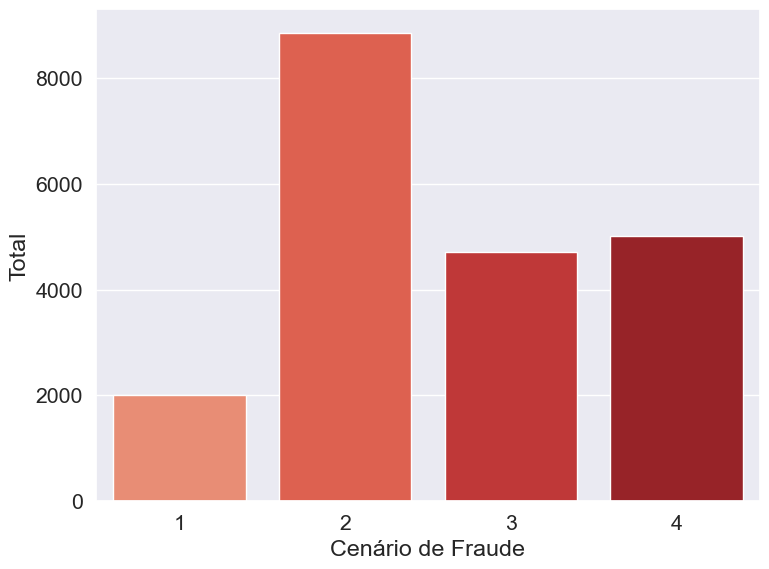

In [38]:
plt.figure(figsize=(8, 6))

sns.countplot(
    x=transactions_df["TX_FRAUD_SCENARIO"].loc[
        transactions_df["TX_FRAUD_SCENARIO"] != 0
    ],
    hue=transactions_df["TX_FRAUD_SCENARIO"].loc[
        transactions_df["TX_FRAUD_SCENARIO"] != 0
    ],
    palette=sns.color_palette("Reds")[2:],
    legend=False,
)

plt.xlabel("Cenário de Fraude")
plt.ylabel("Total")

plt.tight_layout()
plt.show()

### Daily basis number of transactions, fraudulent transactions, and compromised cards

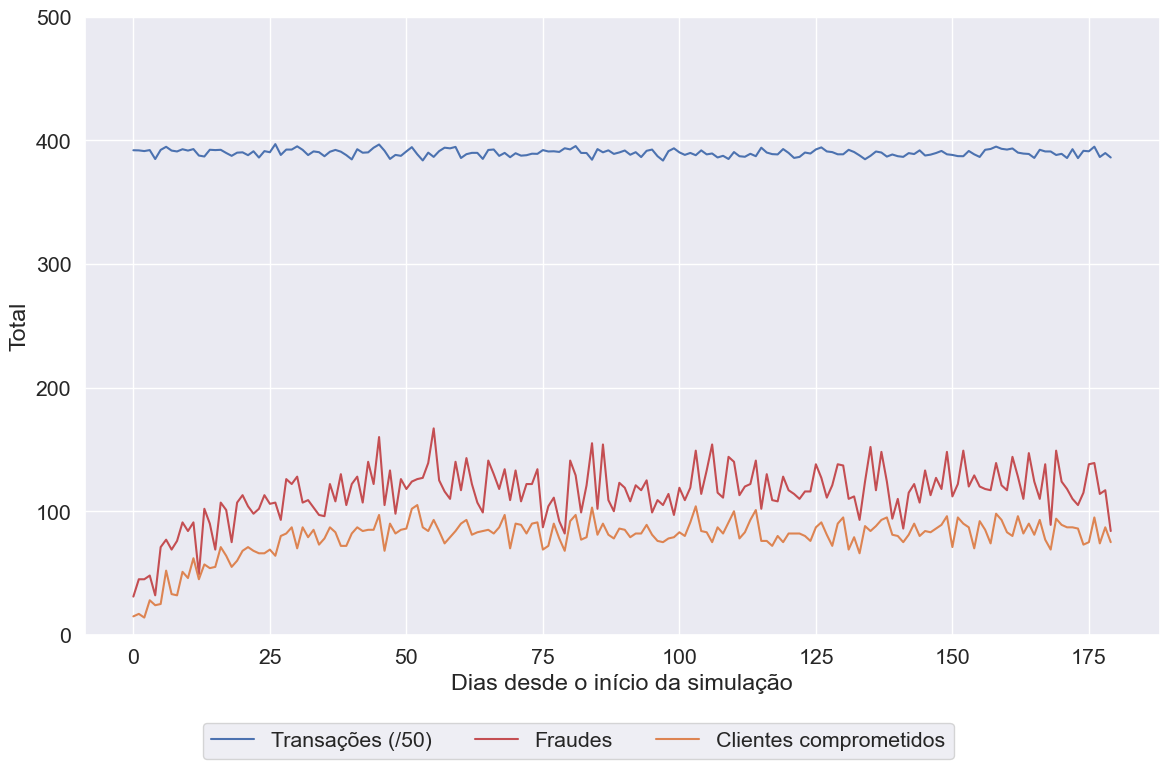

In [39]:
def get_stats(transactions_df):
    # Number of transactions per day
    nb_tx_per_day = transactions_df.groupby(["TX_TIME_DAYS"])["CUSTOMER_ID"].count()
    # Number of fraudulent transactions per day
    nb_fraud_per_day = transactions_df.groupby(["TX_TIME_DAYS"])["TX_FRAUD"].sum()
    # Number of fraudulent cards per day
    nb_fraudcard_per_day = (
        transactions_df[transactions_df["TX_FRAUD"] > 0]
        .groupby(["TX_TIME_DAYS"])
        .CUSTOMER_ID.nunique()
    )

    return (nb_tx_per_day, nb_fraud_per_day, nb_fraudcard_per_day)


(nb_tx_per_day, nb_fraud_per_day, nb_fraudcard_per_day) = get_stats(transactions_df)

n_days = len(nb_tx_per_day)
tx_stats = pd.DataFrame(
    {"value": pd.concat([nb_tx_per_day / 50, nb_fraud_per_day, nb_fraudcard_per_day])}
)
tx_stats["stat_type"] = (
    ["Transações (/50)"] * n_days
    + ["Fraudes"] * n_days
    + ["Clientes comprometidos"] * n_days
)
tx_stats = tx_stats.reset_index()

# Plotting
fig, ax = plt.subplots(1, 1, figsize=(12, 8))

sns_plot = sns.lineplot(
    x="TX_TIME_DAYS",
    y="value",
    data=tx_stats,
    hue="stat_type",
    palette=[sns.color_palette()[0], sns.color_palette()[3], sns.color_palette()[1]],
    hue_order=["Transações (/50)", "Fraudes", "Clientes comprometidos"],
    ax=ax,
)

# plt.title('Total de transações, número de transações fraudulentas \n e número de cartões comprometidos por dia',
#                    fontsize=20)
plt.xlabel("Dias desde o início da simulação")
plt.ylabel("Total")

plt.ylim([0, 500])

handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles=handles,
    labels=labels,
    loc="upper left",
    bbox_to_anchor=(0.1, -0.125),
    ncol=3,
)

plt.tight_layout()
plt.show()

### Transaction amounts per fraud scenario

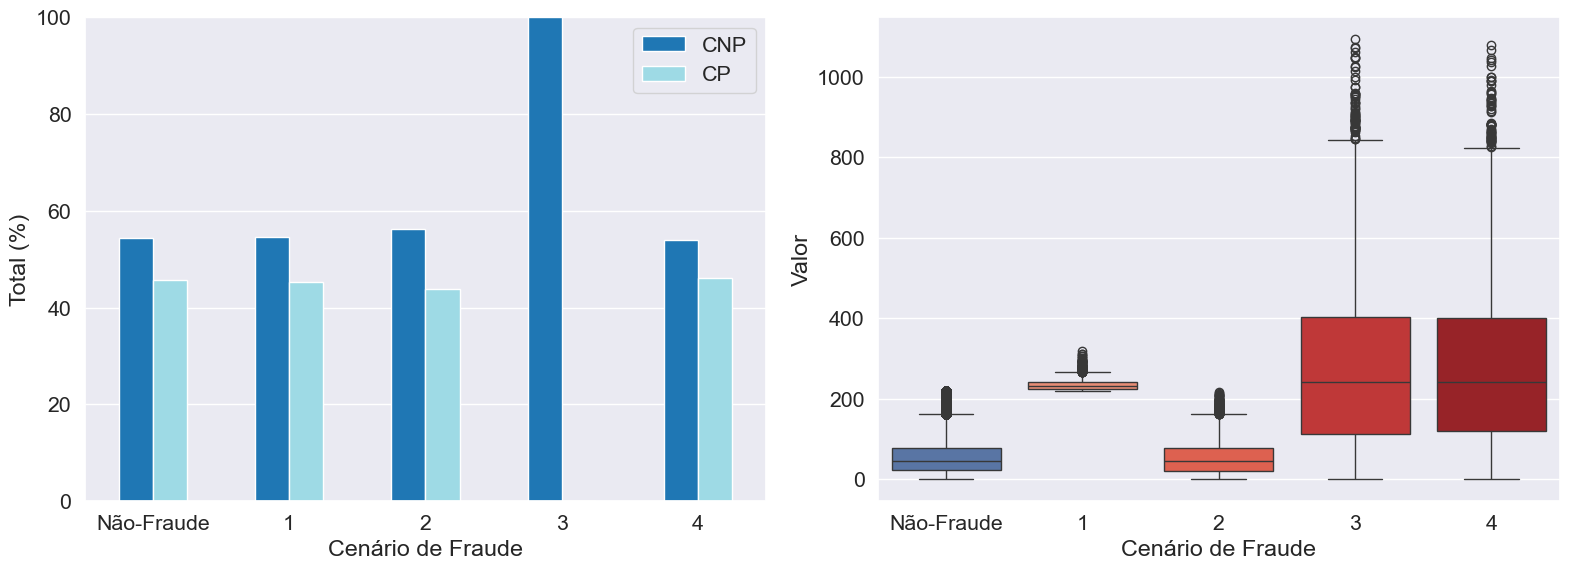

In [40]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6))

pd.crosstab(transactions_df["TX_FRAUD_SCENARIO"], transactions_df["TX_TYPE"]).apply(
    lambda x: 100 * x / x.sum(), axis=1
).plot(
    kind="bar",
    rot=0,
    ax=axs[0],
    xlabel="Cenário de Fraude",
    ylabel="Total (%)",
    colormap="tab20",
)
axs[0].grid(axis="x")
axs[0].set_xticklabels([("Não-Fraude")] + axs[0].get_xticklabels()[1:])
axs[0].legend()
axs[0].set_ylim([0, 100])

sns.boxplot(
    data=transactions_df,
    x="TX_FRAUD_SCENARIO",
    y="TX_AMOUNT",
    hue="TX_FRAUD_SCENARIO",
    legend=False,
    ax=axs[1],
    palette=[sns.color_palette()[0]] + sns.color_palette("Reds")[2:],
)

axs[1].set_xlabel("Cenário de Fraude")
axs[1].set_ylabel("Valor")
axs[1].set_xticklabels([("Não-Fraude")] + axs[1].get_xticklabels()[1:])


plt.tight_layout()
plt.show()

### Distance Calculations

In [41]:
def dist_features(transactions_df):
    billing_locs = transactions_df[["TX_BILL_LAT", "TX_BILL_LONG"]].values.astype(float)
    terminal_locs = transactions_df[["TX_TERM_LAT", "TX_TERM_LONG"]].values.astype(
        float
    )
    shipping_locs = transactions_df[["TX_SHIPP_LAT", "TX_SHIPP_LONG"]].values.astype(
        float
    )

    transactions_df["TX_DIST_BILL_TERM"] = haversine_vector(billing_locs, terminal_locs)
    transactions_df["TX_DIST_BILL_SHIPP"] = haversine_vector(
        billing_locs, shipping_locs
    )

    return transactions_df


transactions_df = dist_features(transactions_df)

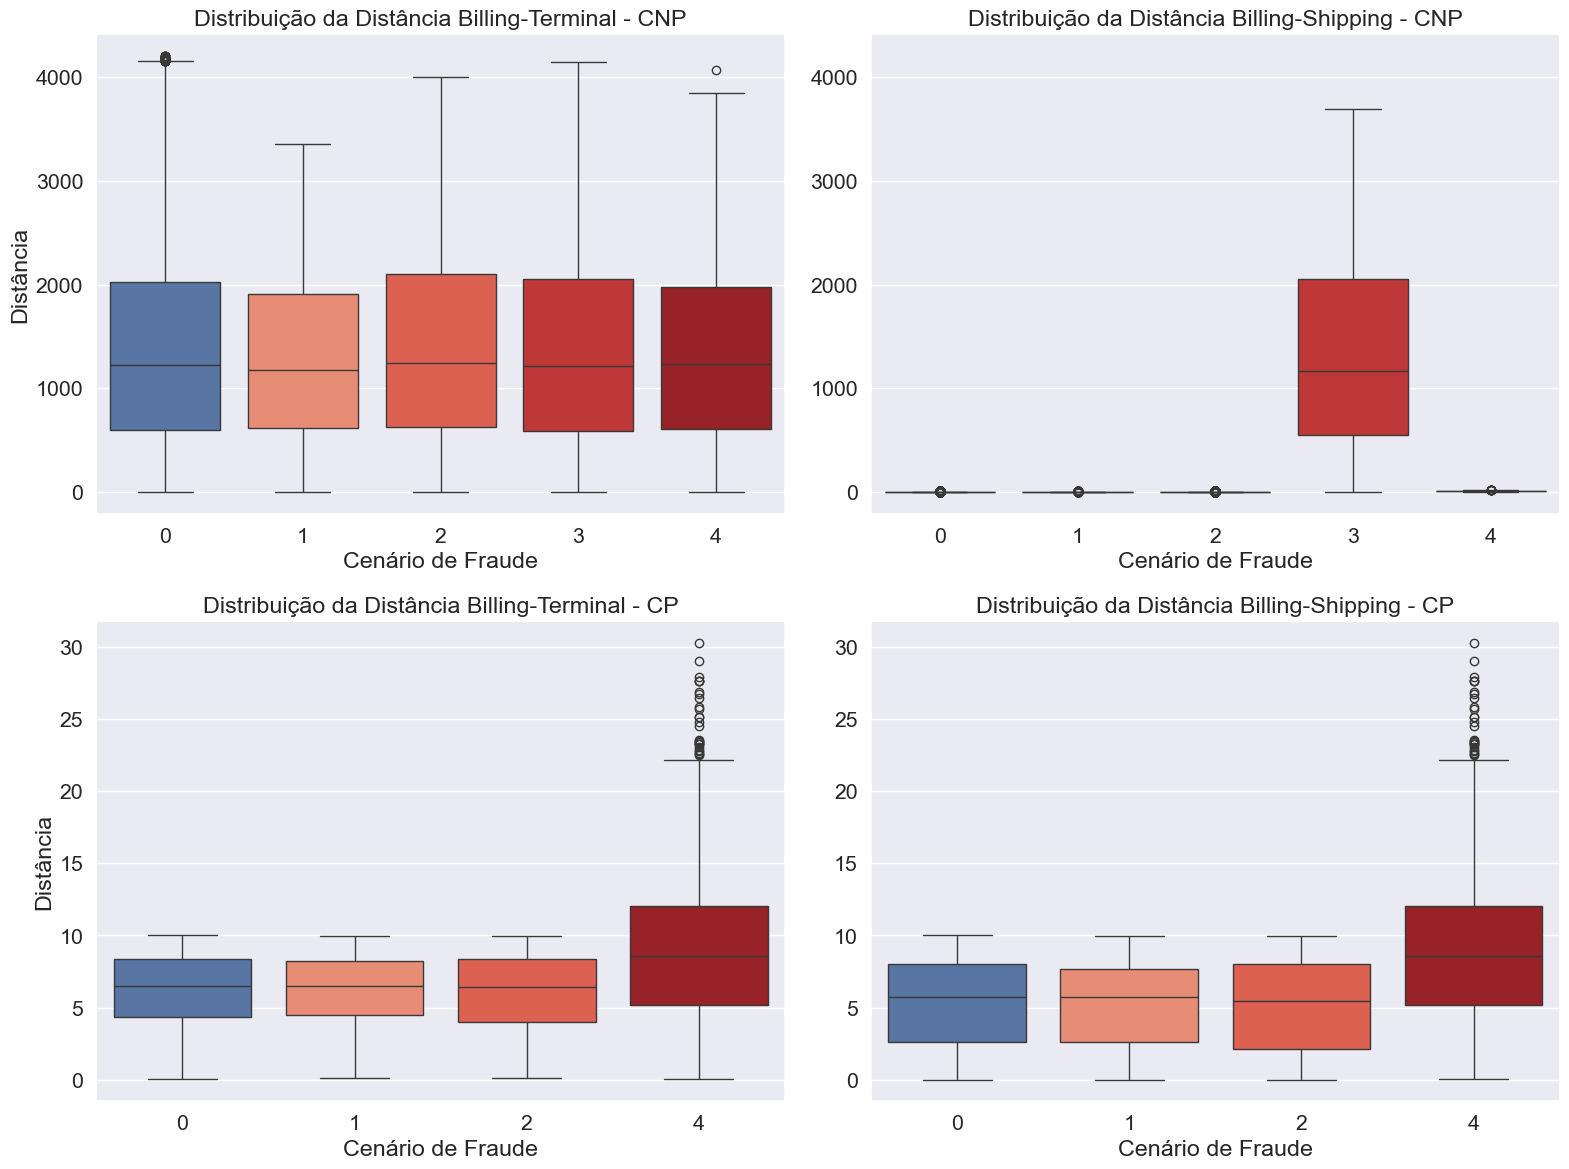

In [42]:
fig, ax = plt.subplots(2, 2, figsize=(16, 12))

cnp_transactions = transactions_df[transactions_df["TX_TYPE"] == "CNP"]
cp_transactions = transactions_df[transactions_df["TX_TYPE"] == "CP"]

sns.boxplot(
    data=cnp_transactions,
    x="TX_FRAUD_SCENARIO",
    y="TX_DIST_BILL_TERM",
    hue="TX_FRAUD_SCENARIO",
    palette=[sns.color_palette()[0]] + sns.color_palette("Reds")[2:],
    legend=False,
    ax=ax[0, 0],
)
ax[0, 0].set_xlabel("Cenário de Fraude")
ax[0, 0].set_ylabel("Distância")
ax[0, 0].set_title("Distribuição da Distância Billing-Terminal - CNP")

sns.boxplot(
    data=cnp_transactions,
    x="TX_FRAUD_SCENARIO",
    y="TX_DIST_BILL_SHIPP",
    hue="TX_FRAUD_SCENARIO",
    palette=[sns.color_palette()[0]] + sns.color_palette("Reds")[2:],
    legend=False,
    ax=ax[0, 1],
)
ax[0, 1].set_xlabel("Cenário de Fraude")
ax[0, 1].set_ylabel("")
ax[0, 1].sharey(ax[0, 0])
ax[0, 1].set_title("Distribuição da Distância Billing-Shipping - CNP")

sns.boxplot(
    data=cp_transactions,
    x="TX_FRAUD_SCENARIO",
    y="TX_DIST_BILL_TERM",
    hue="TX_FRAUD_SCENARIO",
    palette=[sns.color_palette()[0]]
    + sns.color_palette("Reds")[2:4]
    + [sns.color_palette("Reds")[5]],
    legend=False,
    ax=ax[1, 0],
)
ax[1, 0].set_xlabel("Cenário de Fraude")
ax[1, 0].set_ylabel("Distância")
ax[1, 0].set_title("Distribuição da Distância Billing-Terminal - CP")

sns.boxplot(
    data=cp_transactions,
    x="TX_FRAUD_SCENARIO",
    y="TX_DIST_BILL_SHIPP",
    hue="TX_FRAUD_SCENARIO",
    palette=[sns.color_palette()[0]]
    + sns.color_palette("Reds")[2:4]
    + [sns.color_palette("Reds")[5]],
    legend=False,
    ax=ax[1, 1],
)
ax[1, 1].set_xlabel("Cenário de Fraude")
ax[1, 1].set_ylabel("")
ax[1, 1].sharey(ax[1, 0])
ax[1, 1].set_title("Distribuição da Distância Billing-Shipping - CP")

# plt.suptitle('Distance Calculations per Fraud Scenario by Transaction Type')
plt.tight_layout()
plt.show()

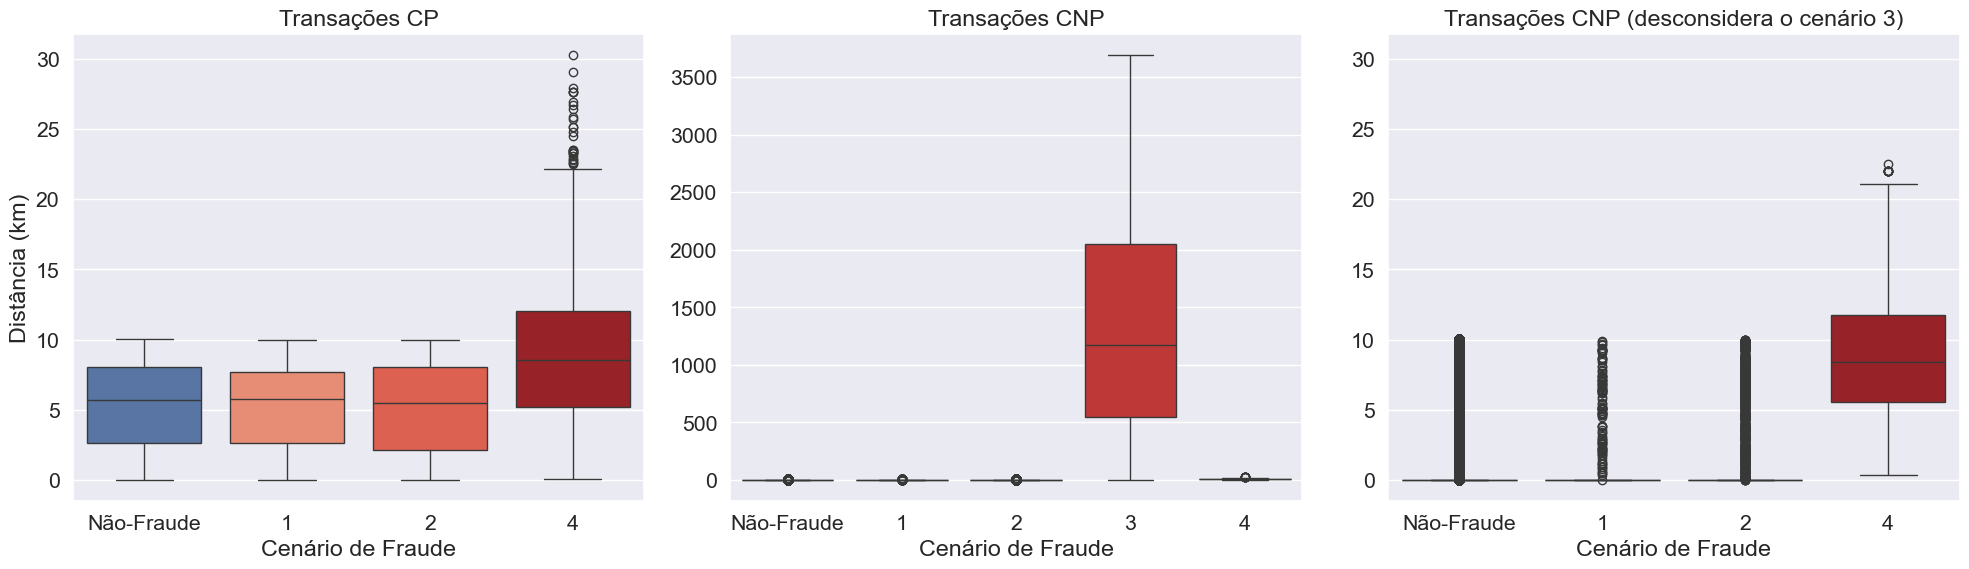

In [43]:
fig, ax = plt.subplots(1, 3, figsize=(20, 6))


sns.boxplot(
    data=cp_transactions,
    x="TX_FRAUD_SCENARIO",
    y="TX_DIST_BILL_SHIPP",
    hue="TX_FRAUD_SCENARIO",
    palette=[sns.color_palette()[0]]
    + sns.color_palette("Reds")[2:4]
    + [sns.color_palette("Reds")[5]],
    legend=False,
    ax=ax[0],
)
ax[0].set_xlabel("Cenário de Fraude")
ax[0].set_ylabel("")
ax[0].set_title("Transações CP")
ax[0].set_xticklabels([("Não-Fraude")] + ax[0].get_xticklabels()[1:])
ax[0].set_ylabel("Distância (km)")

sns.boxplot(
    data=cnp_transactions,
    x="TX_FRAUD_SCENARIO",
    y="TX_DIST_BILL_SHIPP",
    hue="TX_FRAUD_SCENARIO",
    palette=[sns.color_palette()[0]] + sns.color_palette("Reds")[2:],
    legend=False,
    ax=ax[1],
)
ax[1].set_xlabel("Cenário de Fraude")
ax[1].set_title("Transações CNP")
ax[1].set_xticklabels([("Não-Fraude")] + ax[1].get_xticklabels()[1:])
ax[1].set_ylabel("")

sns.boxplot(
    data=cnp_transactions[cnp_transactions["TX_FRAUD_SCENARIO"] != 3],
    x="TX_FRAUD_SCENARIO",
    y="TX_DIST_BILL_SHIPP",
    hue="TX_FRAUD_SCENARIO",
    palette=[sns.color_palette()[0]]
    + sns.color_palette("Reds")[2:4]
    + [sns.color_palette("Reds")[5]],
    legend=False,
    ax=ax[2],
)
ax[2].set_xlabel("Cenário de Fraude")
ax[2].set_ylabel("")
ax[2].set_title("Transações CNP (desconsidera o cenário 3)")
ax[2].set_xticklabels([("Não-Fraude")] + ax[2].get_xticklabels()[1:])
ax[2].sharey(ax[0])


plt.tight_layout()
plt.show()